# 👥 02 · Segmentación RFM y clustering K-Means
Dos formas de segmentar a los clientes y compararlas:
* **Reglas de negocio** sobre los puntajes RFM (fácil de explicar).
* **K-Means** sobre los valores RFM (descubre grupos de forma automática).

### Contenido
1. Carga de ventas limpias
2. Cálculo de Recencia, Frecuencia y Monto
3. Puntajes RFM y segmentos de negocio
4. Clustering con K-Means
5. Perfil de cada cluster
6. Comparación entre ambas segmentaciones
7. Guardado de resultados

In [1]:
# Configuración general e importaciones
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = ROOT / "data" / "retail.db"
PROCESADOS = ROOT / "data" / "processed"
PROCESADOS.mkdir(parents=True, exist_ok=True)

PALETA = ["#6C5CE7", "#00CEC9", "#FD79A8", "#FDCB6E", "#74B9FF", "#55EFC4", "#E17055", "#A29BFE"]
COLOR_SEGMENTO = {
    "Campeones": "#FDCB6E", "Leales": "#00B894", "Nuevos / Prometedores": "#74B9FF",
    "Necesitan atención": "#A29BFE", "En Riesgo": "#E17055", "Perdidos / Hibernando": "#636E72",
}
px.defaults.template = "plotly_white"
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 1100
px.defaults.color_discrete_sequence = PALETA


def estilo(fig, titulo, alto=450):
    """Aplica el mismo formato visual a todos los gráficos del proyecto."""
    fig.update_layout(title=dict(text=f"<b>{titulo}</b>", x=0.01), height=alto,
                      font=dict(family="Segoe UI, Arial", size=13),
                      margin=dict(l=40, r=20, t=70, b=40), legend_title_text="")
    return fig


con = sqlite3.connect(DB)
print(f"Proyecto en: {ROOT}")

Proyecto en: C:\Users\eduar\retail-customer-segmentation-rfm


## 1 · Carga de ventas limpias

In [2]:
# Carga de la tabla limpia
ventas = pd.read_sql("SELECT Invoice, `Customer ID`, Country, InvoiceDate, Ingreso FROM retail_sales_clean",
                     con, parse_dates=["InvoiceDate"])
print(f"{len(ventas):,} líneas de venta · {ventas['Customer ID'].nunique():,} clientes")

769,725 líneas de venta · 5,833 clientes


## 2 · Recencia, Frecuencia y Monto
* **Recency:** días desde la última compra (hasta un día después de la última fecha del dataset).
* **Frequency:** número de facturas distintas.
* **Monetary:** ingreso total gastado (£).

In [3]:
# Cálculo de las métricas RFM por cliente
fecha_corte = ventas["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = ventas.groupby("Customer ID").agg(ultima=("InvoiceDate", "max"), Frequency=("Invoice", "nunique"),
                                        Monetary=("Ingreso", "sum")).reset_index()
rfm["Recency"] = (fecha_corte - rfm["ultima"]).dt.days
rfm["Pais"] = rfm["Customer ID"].map(ventas.groupby("Customer ID")["Country"].agg(lambda s: s.mode().iat[0]))
rfm["Monetary"] = rfm["Monetary"].round(2)
rfm = rfm[["Customer ID", "Pais", "Recency", "Frequency", "Monetary"]]
print(f"Fecha de corte: {fecha_corte:%d-%m-%Y}")
rfm.describe().T

Fecha de corte: 10-12-2011


,count,mean,std,min,25%,50%,75%,max
Recency,"5,833.00",200.10,208.46,1.00,25.00,95.00,379.00,738.00
Frequency,"5,833.00",6.22,12.65,1.00,1.00,3.00,7.00,370.00
Monetary,"5,833.00","2,826.59","13,881.79",2.90,336.40,850.84,"2,207.08","579,128.64"


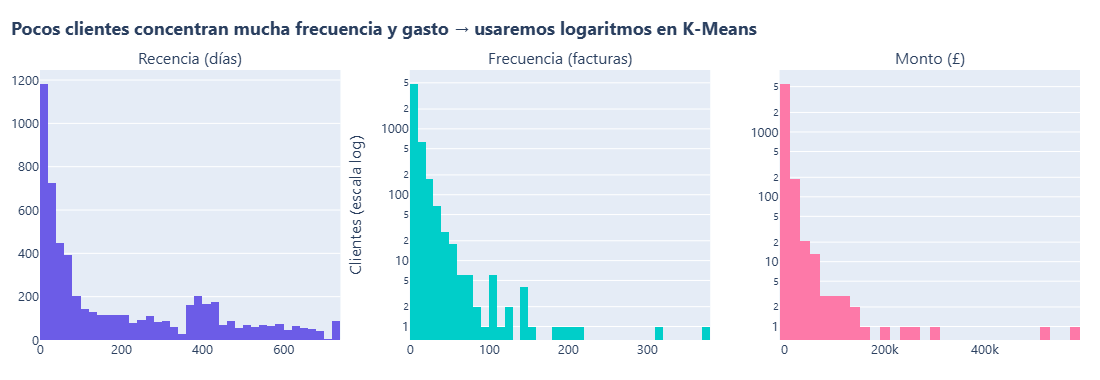

In [4]:
# Distribución de R, F y M: muy sesgadas a la derecha
fig = make_subplots(rows=1, cols=3, subplot_titles=("Recencia (días)", "Frecuencia (facturas)", "Monto (£)"))
for i, col in enumerate(["Recency", "Frequency", "Monetary"], start=1):
    fig.add_trace(go.Histogram(x=rfm[col], nbinsx=50, marker_color=PALETA[i - 1], showlegend=False), row=1, col=i)
fig.update_yaxes(type="log", title_text="Clientes (escala log)", row=1, col=2)
fig.update_yaxes(type="log", row=1, col=3)
estilo(fig, "Pocos clientes concentran mucha frecuencia y gasto → usaremos logaritmos en K-Means", 380).show()

## 3 · Puntajes RFM y segmentos de negocio
Cada métrica recibe un puntaje de 1 a 5 (5 = mejor):
* **R y M:** por quintiles.
* **F:** por rangos fijos (1, 2, 3-4, 5-8, 9+ compras), porque la mayoría de los clientes tiene pocas compras y los quintiles se romperían.

In [5]:
# Puntajes de 1 a 5 para cada métrica
rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.cut(rfm["Frequency"], [0, 1, 2, 4, 8, np.inf], labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_Concat"] = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)
rfm[["R_Score", "F_Score", "M_Score"]].apply(pd.Series.value_counts).sort_index().T

,1,2,3,4,5
R_Score,1167,1166,1167,1166,1167
F_Score,1607,959,1136,1028,1103
M_Score,1167,1166,1167,1166,1167


In [6]:
# Segmentos de negocio según reglas sobre R y F
r, f = rfm["R_Score"], rfm["F_Score"]
condiciones = [(r >= 4) & (f >= 4), (r >= 3) & (f >= 3), (r >= 4) & (f < 3), (r == 3) & (f < 3), (r <= 2) & (f >= 3)]
nombres = ["Campeones", "Leales", "Nuevos / Prometedores", "Necesitan atención", "En Riesgo"]
rfm["Segmento_Negocio"] = np.select(condiciones, nombres, default="Perdidos / Hibernando")

seg = rfm.groupby("Segmento_Negocio").agg(Clientes=("Customer ID", "count"), Ingresos=("Monetary", "sum"),
                                          Recencia=("Recency", "mean"), Frecuencia=("Frequency", "mean"),
                                          Gasto_Medio=("Monetary", "mean")).reset_index()
seg["% Clientes"] = seg["Clientes"] / seg["Clientes"].sum() * 100
seg["% Ingresos"] = seg["Ingresos"] / seg["Ingresos"].sum() * 100
seg = seg.sort_values("% Ingresos", ascending=False)
seg

,Segmento_Negocio,Clientes,Ingresos,Recencia,Frecuencia,Gasto_Medio,% Clientes,% Ingresos
0,Campeones,1385,"11,441,404.87",19.55,16.12,"8,260.94",23.74,69.39
2,Leales,1181,"2,421,537.41",75.98,5.61,"2,050.41",20.25,14.69
1,En Riesgo,701,"1,353,975.92",359.18,5.47,"1,931.49",12.02,8.21
5,Perdidos / Hibernando,1632,"725,504.10",452.90,1.31,444.55,27.98,4.40
4,Nuevos / Prometedores,511,"279,029.58",27.26,1.53,546.05,8.76,1.69
3,Necesitan atención,423,"266,029.34",107.64,1.43,628.91,7.25,1.61


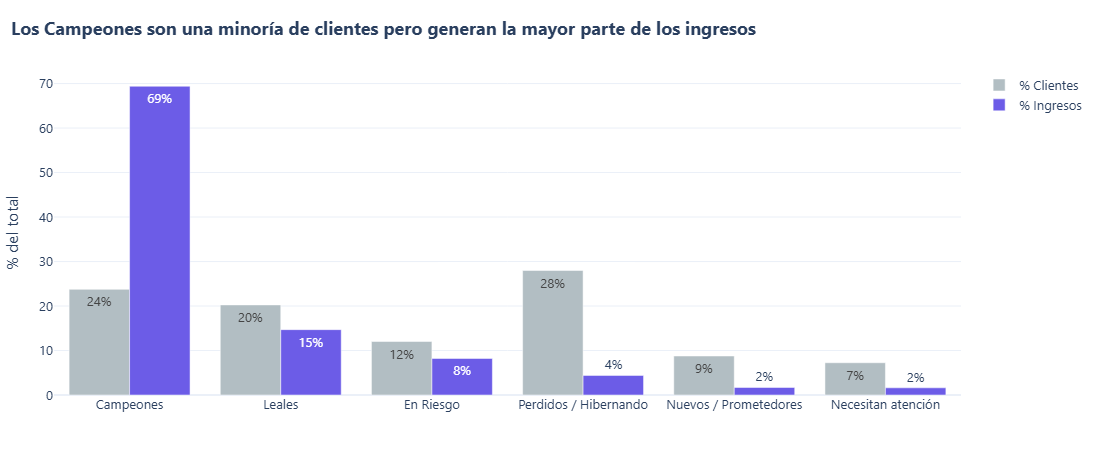

In [7]:
# Peso de cada segmento: % de clientes vs % de ingresos
largo = seg.melt(id_vars="Segmento_Negocio", value_vars=["% Clientes", "% Ingresos"], var_name="Métrica", value_name="Porcentaje")
fig = px.bar(largo, x="Segmento_Negocio", y="Porcentaje", color="Métrica", barmode="group",
             color_discrete_map={"% Clientes": "#B2BEC3", "% Ingresos": "#6C5CE7"},
             text=largo["Porcentaje"].map("{:.0f}%".format), category_orders={"Segmento_Negocio": seg["Segmento_Negocio"].tolist()})
fig.update_layout(xaxis_title="", yaxis_title="% del total")
estilo(fig, "Los Campeones son una minoría de clientes pero generan la mayor parte de los ingresos", 450).show()

## 4 · Clustering con K-Means
K-Means es sensible a la escala y a los valores extremos, por eso:
1. Aplicamos `log1p` a R, F y M para reducir el sesgo.
2. Estandarizamos las variables.
3. Elegimos el número de clusters **k** con el método del codo y el coeficiente de silueta.

In [8]:
# Preparación de variables: logaritmo y estandarización
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = StandardScaler().fit_transform(np.log1p(rfm[["Recency", "Frequency", "Monetary"]]))
print("Matriz lista:", X.shape)

Matriz lista: (5833, 3)


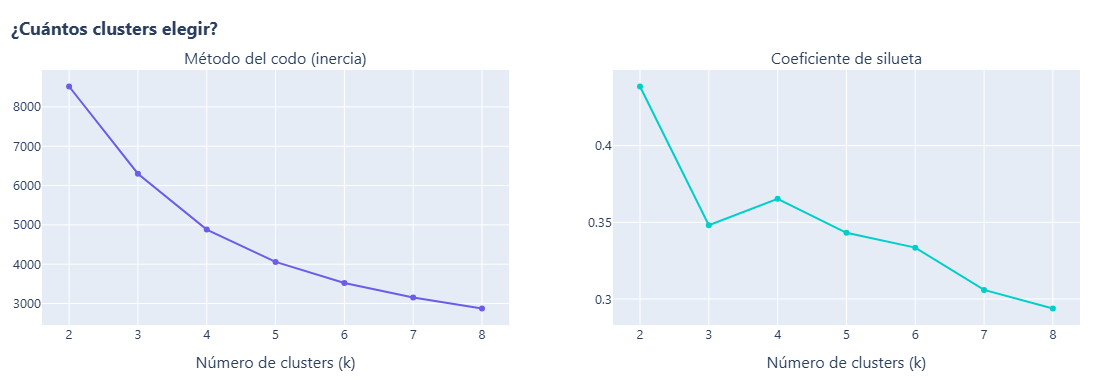

k elegido = 4 (mejor silueta entre 3 y 6: 0.365)


In [9]:
# Selección de k: método del codo y silueta
ks = range(2, 9)
inercia, silueta = [], []
for k in ks:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inercia.append(modelo.inertia_)
    silueta.append(silhouette_score(X, modelo.labels_))

fig = make_subplots(rows=1, cols=2, subplot_titles=("Método del codo (inercia)", "Coeficiente de silueta"))
fig.add_trace(go.Scatter(x=list(ks), y=inercia, mode="lines+markers", line_color="#6C5CE7", showlegend=False), row=1, col=1)
fig.add_trace(go.Scatter(x=list(ks), y=silueta, mode="lines+markers", line_color="#00CEC9", showlegend=False), row=1, col=2)
fig.update_xaxes(title_text="Número de clusters (k)")
estilo(fig, "¿Cuántos clusters elegir?", 380).show()

candidatos = {k: s for k, s in zip(ks, silueta) if 3 <= k <= 6}
K = max(candidatos, key=candidatos.get)
print(f"k elegido = {K} (mejor silueta entre 3 y 6: {candidatos[K]:.3f})")

In [10]:
# Entrenamiento final y orden de los clusters de menor a mayor valor
modelo = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
rfm["Cluster_raw"] = modelo.labels_

medias = np.log1p(rfm.groupby("Cluster_raw")[["Recency", "Frequency", "Monetary"]].mean())
z = (medias - medias.mean()) / medias.std()
puntaje = z["Frequency"] + z["Monetary"] - z["Recency"]
orden = {viejo: nuevo for nuevo, viejo in enumerate(puntaje.sort_values().index)}

NOMBRES = {3: ['Inactivos', 'Regulares', 'VIP'], 4: ['Inactivos', 'Durmientes', 'Activos recientes', 'VIP'], 5: ['Inactivos', 'Ocasionales', 'Regulares', 'Leales', 'VIP'], 6: ['Perdidos', 'Inactivos', 'Ocasionales', 'Regulares', 'Leales', 'VIP']}[K]
rfm["Cluster"] = rfm["Cluster_raw"].map(orden)
rfm["Cluster_Nombre"] = rfm["Cluster"].map(dict(enumerate(NOMBRES)))
rfm = rfm.drop(columns="Cluster_raw")
rfm["Cluster_Nombre"].value_counts()

Cluster_Nombre
Inactivos            1959
Durmientes           1447
Activos recientes    1248
VIP                  1179
Name: count, dtype: int64

## 5 · Perfil de cada cluster
Promedios de R, F y M: así se interpreta qué tipo de cliente es cada grupo.

In [11]:
# Tabla de perfil por cluster
perfil = rfm.groupby(["Cluster", "Cluster_Nombre"]).agg(
    Clientes=("Customer ID", "count"), Recencia=("Recency", "mean"), Frecuencia=("Frequency", "mean"),
    Gasto_Medio=("Monetary", "mean"), Ingresos=("Monetary", "sum")).reset_index()
perfil["% Clientes"] = perfil["Clientes"] / perfil["Clientes"].sum() * 100
perfil["% Ingresos"] = perfil["Ingresos"] / perfil["Ingresos"].sum() * 100
perfil

,Cluster,Cluster_Nombre,Clientes,Recencia,Frecuencia,Gasto_Medio,Ingresos,% Clientes,% Ingresos
0,0,Inactivos,1959,393.82,1.38,315.12,"617,326.22",33.58,3.74
1,1,Durmientes,1447,226.48,5.05,"1,890.04","2,734,880.97",24.81,16.59
2,2,Activos recientes,1248,28.38,3.02,829.52,"1,035,246.35",21.40,6.28
3,3,VIP,1179,27.61,19.11,"10,262.96","12,100,027.68",20.21,73.39


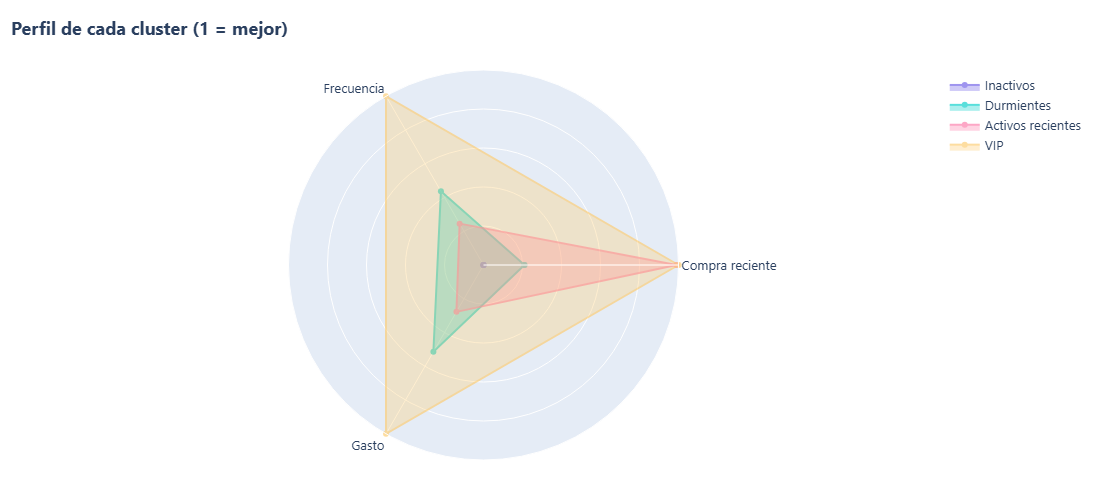

In [12]:
# Gráfico de radar: comparación de perfiles
medias_log = np.log1p(perfil[["Recencia", "Frecuencia", "Gasto_Medio"]])
normal = (medias_log - medias_log.min()) / (medias_log.max() - medias_log.min())
normal["Recencia"] = 1 - normal["Recencia"]
ejes = ["Compra reciente", "Frecuencia", "Gasto"]

fig = go.Figure()
for i, fila in perfil.iterrows():
    v = normal.loc[i, ["Recencia", "Frecuencia", "Gasto_Medio"]].tolist()
    fig.add_trace(go.Scatterpolar(r=v + v[:1], theta=ejes + ejes[:1], fill="toself", name=fila["Cluster_Nombre"],
                                  line_color=PALETA[i % len(PALETA)], opacity=0.65))
fig.update_layout(polar=dict(radialaxis=dict(visible=True, range=[0, 1], showticklabels=False)))
estilo(fig, "Perfil de cada cluster (1 = mejor)", 500).show()

### 🧭 Cómo leer los clusters
| Cluster | Quiénes son | Acción sugerida |
|---|---|---|
| **Inactivos** | Casi 1 compra y más de un año sin volver; aportan muy poco ingreso | Campaña de reactivación de bajo costo o descartar |
| **Durmientes** | Compraban bastante (≈5 compras, ticket alto) pero llevan ~7 meses sin volver | **Prioridad de reactivación:** ofertas personalizadas |
| **Activos recientes** | Compraron hace ~1 mes, pocas compras y gasto moderado | Fidelizar para que pasen a VIP |
| **VIP** | Compran muy seguido (≈19 compras) y concentran la mayor parte del ingreso | Programa de lealtad, atención preferente |

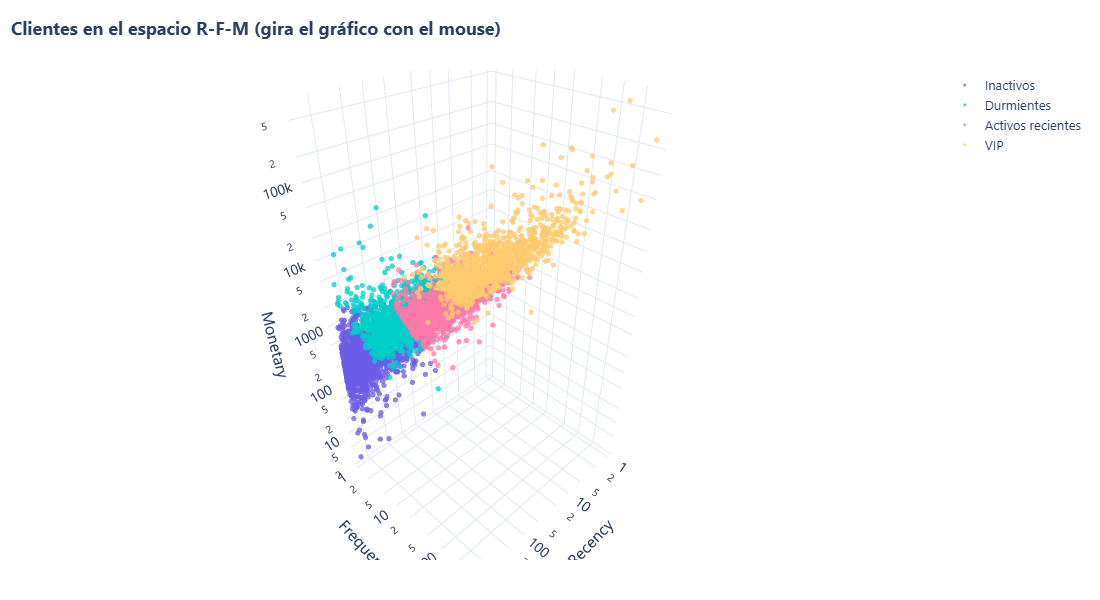

In [13]:
# Mapa 3D interactivo de los clusters (ejes logarítmicos)
fig = px.scatter_3d(rfm, x="Recency", y="Frequency", z="Monetary", color="Cluster_Nombre", log_x=True, log_y=True, log_z=True,
                    hover_data=["Customer ID", "Segmento_Negocio"], opacity=0.75,
                    category_orders={"Cluster_Nombre": NOMBRES})
fig.update_traces(marker_size=3)
estilo(fig, "Clientes en el espacio R-F-M (gira el gráfico con el mouse)", 600).show()

## 6 · Comparación entre ambas segmentaciones
Si coinciden bastante, las dos formas de segmentar cuentan la misma historia.

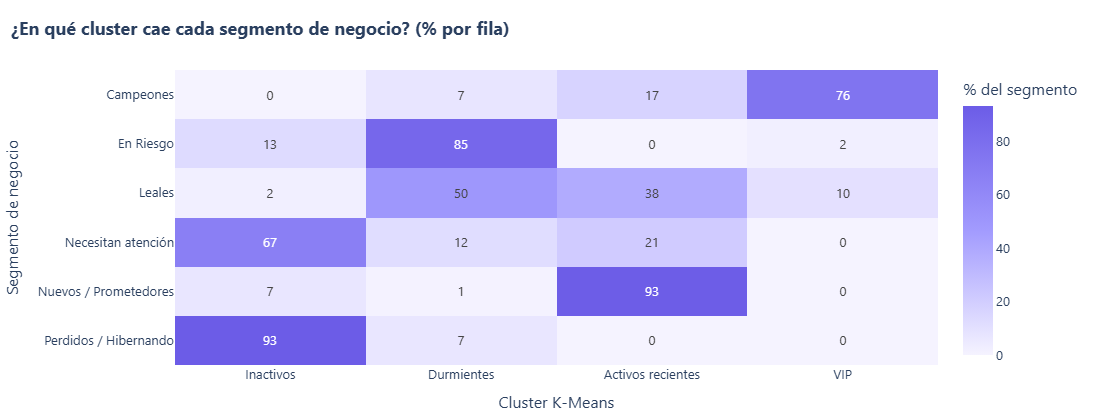

In [14]:
# Cruce entre segmentos de negocio y clusters
cruce = pd.crosstab(rfm["Segmento_Negocio"], rfm["Cluster_Nombre"])[NOMBRES]
cruce_pct = cruce.div(cruce.sum(axis=1), axis=0) * 100
fig = px.imshow(cruce_pct, text_auto=".0f", aspect="auto", color_continuous_scale=["#F5F3FF", "#A29BFE", "#6C5CE7"],
                labels=dict(x="Cluster K-Means", y="Segmento de negocio", color="% del segmento"))
estilo(fig, "¿En qué cluster cae cada segmento de negocio? (% por fila)", 420).show()

## 7 · Guardado de resultados

In [15]:
# Guardado en SQLite y en CSV para el dashboard
rfm.to_sql("rfm_clusters", con, if_exists="replace", index=False)
rfm.to_csv(PROCESADOS / "rfm_clusters.csv", index=False)
print(f"Guardados {len(rfm):,} clientes en rfm_clusters (BD y CSV)")
rfm.head()

Guardados 5,833 clientes en rfm_clusters (BD y CSV)


,Customer ID,Pais,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Concat,Segmento_Negocio,Cluster,Cluster_Nombre
0,12346,United Kingdom,529,2,169.36,1,2,1,121,Perdidos / Hibernando,0,Inactivos
1,12347,Iceland,2,8,"4,921.53",5,4,5,545,Campeones,3,VIP
2,12348,Finland,75,5,"1,658.40",3,4,4,344,Leales,1,Durmientes
3,12349,Italy,19,3,"3,678.69",5,3,5,535,Leales,2,Activos recientes
4,12350,Norway,310,1,294.40,2,1,2,212,Perdidos / Hibernando,0,Inactivos


In [16]:
# Hallazgos clave de la segmentación
camp = seg.set_index("Segmento_Negocio").loc["Campeones"]
riesgo = seg[seg["Segmento_Negocio"].isin(["En Riesgo", "Perdidos / Hibernando"])]
vip = perfil.iloc[-1]
print(f"🏆 Campeones: {camp['% Clientes']:.0f}% de los clientes generan el {camp['% Ingresos']:.0f}% de los ingresos")
print(f"⚠️ En riesgo o perdidos: {riesgo['% Clientes'].sum():.0f}% de los clientes ({riesgo['Clientes'].sum():,}) → oportunidad de reactivación")
print(f"💎 Cluster {vip['Cluster_Nombre']}: {vip['% Clientes']:.0f}% de los clientes, {vip['% Ingresos']:.0f}% de los ingresos")
print(f"📐 K-Means con k={K}, silueta={candidatos[K]:.2f}")

🏆 Campeones: 24% de los clientes generan el 69% de los ingresos
⚠️ En riesgo o perdidos: 40% de los clientes (2,333) → oportunidad de reactivación
💎 Cluster VIP: 20% de los clientes, 73% de los ingresos
📐 K-Means con k=4, silueta=0.37
